# Lab 3: Binary Classification for Ticket Escalation

**Objective:** Build and evaluate binary classifiers for a synthetic service-ticket escalation dataset. The focus is on selecting evaluation metrics and decision thresholds according to the cost of mistakes.

**Target:** `escalated` (1 = escalated, 0 = not escalated).  
**Positive class:** `1` (an escalated ticket).

> Keep this notebook in the same directory as `classification_escalation.csv`.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)

RANDOM_STATE = 42

## 2. Load and inspect the dataset

The dataset contains synthetic service tickets. Each row is one ticket.

In [2]:
df = pd.read_csv("classification_escalation.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\nData types and non-null counts:")
df.info()
print("\nMissing values:")
display(df.isna().sum().rename("missing_count").to_frame())
print("\nTarget distribution (counts):")
display(df["escalated"].value_counts().sort_index().rename("count").to_frame())
print("\nTarget prevalence (proportions):")
display(df["escalated"].value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Dataset shape: (900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    object 
 3   channel                 900 non-null    object 
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 42.3+ KB

Missing values:


,missing_count
complexity_score,0
team_experience_years,31
priority,18
channel,0
customer_tenure_months,22
escalated,0



Target distribution (counts):


,count
escalated,
0,714
1,186



Target prevalence (proportions):


,proportion
escalated,
0,0.793333
1,0.206667


### Initial interpretation

This is a **binary classification** task because the target variable has two possible classes: 0 (not escalated) and 1 (escalated). The positive class is **1 = escalated**, because the purpose is to identify tickets that need escalation.

The dataset is not perfectly balanced. Therefore, accuracy alone may hide poor detection of the less common positive class. Recall, precision, F1, ROC-AUC, and the costs of false positives and false negatives are also important.

## 3. Define features and split the data

The split follows the lab instructions exactly: `test_size=0.25`, `random_state=42`, and `stratify=y`.

In [3]:
target = "escalated"
X = df.drop(columns=[target])
y = df[target]

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Training target proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Test target proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Numeric features: ['complexity_score', 'team_experience_years', 'customer_tenure_months']
Categorical features: ['priority', 'channel']
Training set: (675, 5)
Test set: (225, 5)
Training target proportions:


,proportion
escalated,
0,0.792593
1,0.207407


Test target proportions:


,proportion
escalated,
0,0.795556
1,0.204444


## 4. Build preprocessing pipelines

Numeric columns: median imputation followed by standard scaling.  
Categorical columns: most-frequent imputation followed by one-hot encoding.

Preprocessing is placed inside each model pipeline so that imputers, scalers, and encoders are fitted only on the training data during model fitting and cross-validation.

In [4]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

## 5. Train the four required classifiers

The models are: majority-class baseline, Logistic Regression, Linear Discriminant Analysis (LDA), and k-Nearest Neighbors with k=15.

In [5]:
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN (k=15)": KNeighborsClassifier(n_neighbors=15)
}

fitted_models = {}
comparison_rows = []

for model_name, classifier in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    model_pipeline.fit(X_train, y_train)
    fitted_models[model_name] = model_pipeline

    predictions = model_pipeline.predict(X_test)
    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0)
    }

    if hasattr(model_pipeline, "predict_proba"):
        probabilities = model_pipeline.predict_proba(X_test)[:, 1]
        row["ROC-AUC"] = roc_auc_score(y_test, probabilities)
    else:
        row["ROC-AUC"] = np.nan

    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows).set_index("Model")
display(comparison_df.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Majority baseline,0.7956,0.00,0.0000,0.0000,0.5000
Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
LDA,0.8222,0.75,0.1957,0.3103,0.8090
KNN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


### Classification report

The following report gives class-level precision, recall, and F1 for each fitted classifier.

In [6]:
for model_name, model_pipeline in fitted_models.items():
    print(f"\n{model_name}")
    print(classification_report(
        y_test,
        model_pipeline.predict(X_test),
        zero_division=0
    ))


Majority baseline
              precision    recall  f1-score   support

           0       0.80      1.00      0.89       179
           1       0.00      0.00      0.00        46

    accuracy                           0.80       225
   macro avg       0.40      0.50      0.44       225
weighted avg       0.63      0.80      0.70       225


Logistic Regression
              precision    recall  f1-score   support

           0       0.83      0.98      0.90       179
           1       0.75      0.20      0.31        46

    accuracy                           0.82       225
   macro avg       0.79      0.59      0.60       225
weighted avg       0.81      0.82      0.78       225


LDA
              precision    recall  f1-score   support

           0       0.83      0.98      0.90       179
           1       0.75      0.20      0.31        46

    accuracy                           0.82       225
   macro avg       0.79      0.59      0.60       225
weighted avg       0.81      

## 6. Logistic Regression: confusion matrix and ROC curve

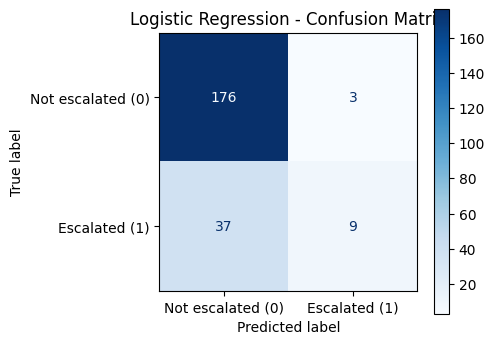

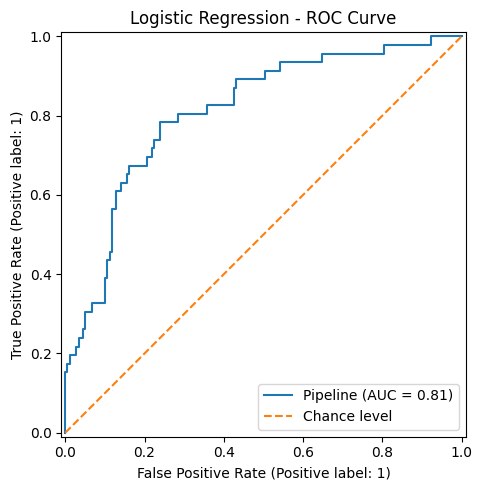

Logistic Regression ROC-AUC: 0.8111


In [7]:
logistic_model = fitted_models["Logistic Regression"]
logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, logistic_predictions,
    display_labels=["Not escalated (0)", "Escalated (1)"],
    cmap="Blues",
    ax=ax
)
ax.set_title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(logistic_model, X_test, y_test, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance level")
ax.set_title("Logistic Regression - ROC Curve")
ax.legend()
plt.tight_layout()
plt.show()

print("Logistic Regression ROC-AUC:", round(
    roc_auc_score(y_test, logistic_probabilities), 4
))

## 7. Evaluate decision thresholds

For Logistic Regression, evaluate thresholds 0.20, 0.30, 0.40, 0.50, 0.60, and 0.70. A ticket is predicted as escalated when its predicted probability is greater than or equal to the threshold.

- FP = false positives: tickets predicted escalated but actually not escalated.
- FN = false negatives: tickets predicted not escalated but actually escalated.
- Illustrative cost = `5 × FN + 1 × FP`.

In [8]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
threshold_rows = []

for threshold in thresholds:
    threshold_predictions = (logistic_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test, threshold_predictions, labels=[0, 1]
    ).ravel()

    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, threshold_predictions, zero_division=0),
        "Recall": recall_score(y_test, threshold_predictions, zero_division=0),
        "F1": f1_score(y_test, threshold_predictions, zero_division=0),
        "FP": fp,
        "FN": fn,
        "Cost (5*FN + FP)": 5 * fn + fp
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(4))

best_threshold_row = threshold_df.loc[threshold_df["Cost (5*FN + FP)"].idxmin()]
print("Lowest-cost threshold on this test set:", best_threshold_row["Threshold"])
print("Illustrative cost:", int(best_threshold_row["Cost (5*FN + FP)"]))

,Threshold,Precision,Recall,F1,FP,FN,Cost (5*FN + FP)
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230


Lowest-cost threshold on this test set: 0.2
Illustrative cost: 98


### What happens when the threshold is lowered?

Lowering the threshold makes the classifier more willing to predict the positive class (escalated). This usually increases recall because more truly escalated tickets are detected, but it can also increase false positives and reduce precision. The table above shows the measured trade-off on this test set.

**Caution:** Choosing a threshold by repeatedly checking the test set can make the reported minimum cost optimistic. The test set is intended for final evaluation, not repeated tuning. A separate validation set or cross-validation-based threshold selection should be used for model selection, followed by one final test evaluation.

## 8. Cost-sensitive decision at posterior probability 0.30

Let `p = P(escalated | x)`.

- Expected cost of escalating = `1 × (1 - p)` because a false positive costs 1.
- Expected cost of not escalating = `5 × p` because a false negative costs 5.

At p = 0.30:

In [9]:
p = 0.30
cost_escalate = 1 * (1 - p)
cost_do_not_escalate = 5 * p

print("Expected cost of escalating:", cost_escalate)
print("Expected cost of not escalating:", cost_do_not_escalate)

# Escalate when 1*(1-p) <= 5*p
# 1 - p <= 5p  -> 1 <= 6p -> p >= 1/6
cost_sensitive_threshold = 1 / 6
print("Cost-sensitive threshold:", cost_sensitive_threshold)
print("As a percentage:", round(cost_sensitive_threshold * 100, 2), "%")

Expected cost of escalating: 0.7
Expected cost of not escalating: 1.5
Cost-sensitive threshold: 0.16666666666666666
As a percentage: 16.67 %


**Interpretation:** At posterior probability 0.30, escalating has expected cost 0.70, while not escalating has expected cost 1.50. Therefore, escalating is the lower-cost decision under the illustrative costs.

The decision threshold is derived by setting the two expected costs equal:

`1(1 - p) = 5p`  
`1 - p = 5p`  
`1 = 6p`  
`p = 1/6 ≈ 0.1667`

Thus, under these simplified costs, predict escalation when the posterior probability is at least approximately 0.1667.

## 9. Stratified 5-fold cross-validation and KNN tuning

Use only the training set for cross-validation. Tune k over 5, 9, 15, 21, and 31 using F1 as required.

In [10]:
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid={"classifier__n_neighbors": [5, 9, 15, 21, 31]},
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

knn_grid.fit(X_train, y_train)

print("Best k:", knn_grid.best_params_["classifier__n_neighbors"])
print("Best mean CV F1:", round(knn_grid.best_score_, 4))

cv_results = pd.DataFrame(knn_grid.cv_results_)[
    ["param_classifier__n_neighbors", "mean_test_score", "std_test_score", "rank_test_score"]
].rename(columns={
    "param_classifier__n_neighbors": "k",
    "mean_test_score": "Mean CV F1",
    "std_test_score": "Std CV F1",
    "rank_test_score": "Rank"
}).sort_values("k")

display(cv_results.round(4))

Best k: 5
Best mean CV F1: 0.2433


,k,Mean CV F1,Std CV F1,Rank
0,5,0.2433,0.0946,1
1,9,0.1976,0.0652,2
2,15,0.1596,0.0655,3
3,21,0.1458,0.0564,4
4,31,0.1122,0.0397,5


## 10. Answers to the lab questions

In [11]:
# Derive answers from the computed evaluation tables.
recall_winner = comparison_df["Recall"].idxmax()
precision_winner = comparison_df["Precision"].idxmax()
f1_winner = comparison_df["F1"].idxmax()
cost_winner = threshold_df.loc[threshold_df["Cost (5*FN + FP)"].idxmin()]

print("1. Why can accuracy alone be misleading?")
print(
    "The target classes are imbalanced, so a model can achieve seemingly high "
    "accuracy by favoring the majority class while missing escalated tickets. "
    "Recall, precision, F1, ROC-AUC, and error costs give a fuller picture."
)

print("\n2. Strongest recall:", recall_winner,
      f"({comparison_df.loc[recall_winner, 'Recall']:.4f})")
print("   Strongest precision:", precision_winner,
      f"({comparison_df.loc[precision_winner, 'Precision']:.4f})")
print("   Strongest F1:", f1_winner,
      f"({comparison_df.loc[f1_winner, 'F1']:.4f})")

print("\n3. What changes when the threshold is lowered?")
print(
    "The classifier predicts more tickets as escalated. Recall generally rises, "
    "while false positives can increase and precision can fall."
)

print("\n4. Minimum-cost threshold on this test set:",
      cost_winner["Threshold"],
      "| FP:", int(cost_winner["FP"]),
      "| FN:", int(cost_winner["FN"]),
      "| Cost:", int(cost_winner["Cost (5*FN + FP)"]))
print(
    "Repeatedly tuning on the test set can overfit decisions to this particular "
    "sample and produce an optimistic cost estimate."
)

print("\n5. Bayesian terms in this ticket scenario:")
print(
    "Prior: escalation probability before considering this ticket's features. "
    "Likelihood: how probable the observed features are under an escalated or "
    "non-escalated ticket. Posterior: updated probability of escalation after "
    "observing the features. Evidence: overall probability of observing those "
    "features across the possible classes."
)

print("\n6. At posterior 0.30:")
print(f"   Cost if escalate = {cost_escalate:.2f}")
print(f"   Cost if do not escalate = {cost_do_not_escalate:.2f}")
print(f"   Cost-sensitive threshold = {cost_sensitive_threshold:.4f}")

print("\n7. Deployment recommendation:")
print(
    "Do not deploy based on one test score alone. Select a model using the "
    "operational cost of errors and validation data, confirm threshold behavior, "
    "check calibration, fairness, privacy, data quality, and performance drift, "
    "and run a monitored pilot with human oversight."
)

1. Why can accuracy alone be misleading?
The target classes are imbalanced, so a model can achieve seemingly high accuracy by favoring the majority class while missing escalated tickets. Recall, precision, F1, ROC-AUC, and error costs give a fuller picture.

2. Strongest recall: Logistic Regression (0.1957)
   Strongest precision: Logistic Regression (0.7500)
   Strongest F1: Logistic Regression (0.3103)

3. What changes when the threshold is lowered?
The classifier predicts more tickets as escalated. Recall generally rises, while false positives can increase and precision can fall.

4. Minimum-cost threshold on this test set: 0.2 | FP: 48 | FN: 10 | Cost: 98
Repeatedly tuning on the test set can overfit decisions to this particular sample and produce an optimistic cost estimate.

5. Bayesian terms in this ticket scenario:
Prior: escalation probability before considering this ticket's features. Likelihood: how probable the observed features are under an escalated or non-escalated ticke

## 11. Recommendation (300–500 words)

The recommendation below is based on the model comparison and threshold results produced by this notebook. It should be reviewed with the operational team before any real deployment.

In [12]:
best_cost_threshold = float(cost_winner["Threshold"])
best_cost = int(cost_winner["Cost (5*FN + FP)"])
best_cost_fp = int(cost_winner["FP"])
best_cost_fn = int(cost_winner["FN"])
best_knn_k = int(knn_grid.best_params_["classifier__n_neighbors"])

recommendation = f'''
For this synthetic ticket-escalation task, the positive class is an escalated
ticket (escalated = 1). The dataset contains {len(df)} records, and
{(y.mean()*100):.1f}% belong to the positive class. Because the classes are
unequal, accuracy should not be used alone. A model could classify many
non-escalated tickets correctly while still missing tickets that genuinely
require escalation. Recall is especially important when missed escalations
are costly, while precision indicates how many flagged tickets are truly
escalated. F1 summarizes the precision-recall balance, and ROC-AUC measures
ranking performance across thresholds.

The test-set comparison should be interpreted using all reported metrics.
The highest-recall classifier in this run is {recall_winner}; the highest-
precision classifier is {precision_winner}; and the highest-F1 classifier is
{f1_winner}. These winners need not be the same. The majority-class model is
a useful baseline, not a suitable automatic escalation solution if it fails
to identify positive cases. Logistic Regression is useful for this lab because
it provides probability estimates, supports threshold analysis, and is
relatively interpretable. The threshold table shows the trade-off between
finding more escalated tickets and creating additional false alarms.

Using the illustrative cost function 5*FN + FP, the lowest-cost threshold
among those tested on this test set is {best_cost_threshold:.2f}, with
{best_cost_fn} false negatives and {best_cost_fp} false positives, giving a
cost of {best_cost}. This result reflects the stated assumption that a missed
escalation costs five times as much as a false alarm. The theoretical
cost-sensitive threshold under these costs is 1/6 (about 0.1667), obtained
by comparing the expected cost of escalating with the expected cost of not
escalating. The tested threshold grid does not include that exact value.

For KNN, stratified five-fold cross-validation on the training set selected
k = {best_knn_k}, using F1. Cross-validation helps estimate performance more
reliably than a single split, while keeping the test set separate is important.

I would not recommend immediate automatic deployment based only on this
synthetic dataset. Before deployment, the university or service team should
validate the data definitions and error costs with domain experts, evaluate
probability calibration, test on newer and representative real-world data,
check performance across relevant customer and channel groups, and monitor
false negatives, false positives, and drift. Privacy, access control,
transparency, and a human review/appeal path are also required. A limited,
monitored pilot with human oversight is the safest next step.
'''.strip()

word_count = len(recommendation.split())
print("Word count:", word_count)
print(recommendation)
assert 300 <= word_count <= 500, f"Recommendation must be 300-500 words, got {word_count}"

Word count: 382
For this synthetic ticket-escalation task, the positive class is an escalated
ticket (escalated = 1). The dataset contains 900 records, and
20.7% belong to the positive class. Because the classes are
unequal, accuracy should not be used alone. A model could classify many
non-escalated tickets correctly while still missing tickets that genuinely
require escalation. Recall is especially important when missed escalations
are costly, while precision indicates how many flagged tickets are truly
escalated. F1 summarizes the precision-recall balance, and ROC-AUC measures
ranking performance across thresholds.

The test-set comparison should be interpreted using all reported metrics.
The highest-recall classifier in this run is Logistic Regression; the highest-
precision classifier is Logistic Regression; and the highest-F1 classifier is
Logistic Regression. These winners need not be the same. The majority-class model is
a useful baseline, not a suitable automatic escalation so

## 12. Conclusion

This lab compared four binary classifiers, evaluated Logistic Regression thresholds using an explicit false-negative/false-positive cost function, and tuned KNN with stratified cross-validation. The best operational choice depends on the relative consequences of missed escalations and unnecessary escalations, not accuracy alone.

